In [1]:
import pandas as pd
import requests
import matplotlib.pyplot as plt


Task 1: Temperature
First request the daily mean air temperture for all of 2025.
The specifications you will need for this is:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}
Otherwise you can follow the example from frost.met.no on how to get the data
when using Python
Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis
Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

Data er hentet fra frost.met.no!

Sammendrag for 2025:
  Statistikk  Temperatur (°C)
0       Mean              7.9
1     Median              8.4
2        Min            -15.5
3        Max             23.7


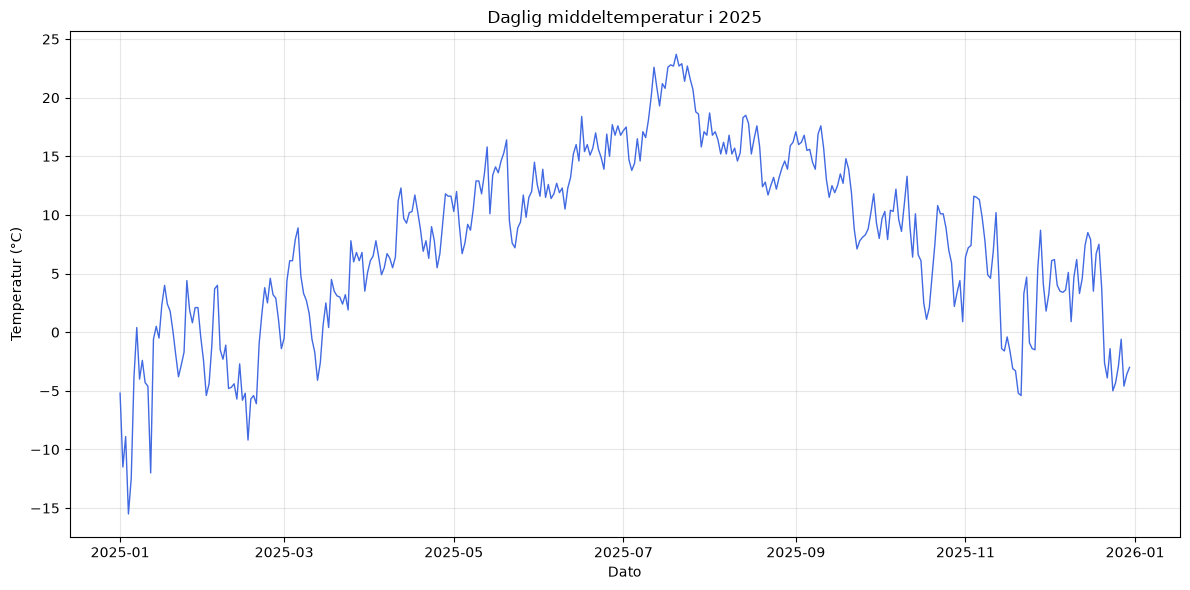

In [8]:



#client_id = '<INSERT CLIENT ID HERE>'
with open("client_id.txt", "r") as f:
    client_id = f.read().strip()


endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

#HTTP request
r = requests.get(
    endpoint,
    params = parameters, 
    auth=(client_id, '')
)

#Henter JSON data
json = r.json()

if r.status_code == 200:
    
    print('Data er hentet fra frost.met.no!')

    data =json['data']

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])

        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']

        rows.append(row)

    df = pd.concat(rows, ignore_index=True)
    df = df[df['timeOffset'] == 'PT0H']

else:

    print(f"Feil! Returnerte statuskode {r.status_code}")
    print(json['error']['message'])
    raise SystemExit("Stopper fordi data ikke ble hentet")

df['referenceTime'] = pd.to_datetime(df['referenceTime'])

temps = df['value']


summary = pd.DataFrame({
    'Statistikk': ['Mean', 'Median', 'Min', 'Max'],
    'Temperatur (°C)': [
        temps.mean(),
        temps.median(),
        temps.min(),
        temps.max()
    ]
})

print("\nSammendrag for 2025:")
print(summary.round(2))

plt.figure(figsize=(12, 6))

plt.plot(
    df['referenceTime'],
    temps,
    color='royalblue',
    linewidth=1
)

plt.title('Daglig middeltemperatur i 2025')
plt.xlabel('Dato')
plt.ylabel('Temperatur (°C)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Task 2: Precipitation
Request data for precipitation for the same time period, specifically measurements
of precipitation over 24 hours. This is coded as sum(precipitation_amount
P1D) in the database
Create a new plot that shows both the temperature from task 1 and the precipitation
in the same plot
Think through how to display both values in a way that is useful and looks good
Consider which type of plot works best for each measurement (scatter, line, bar,
pie chart, ...?)


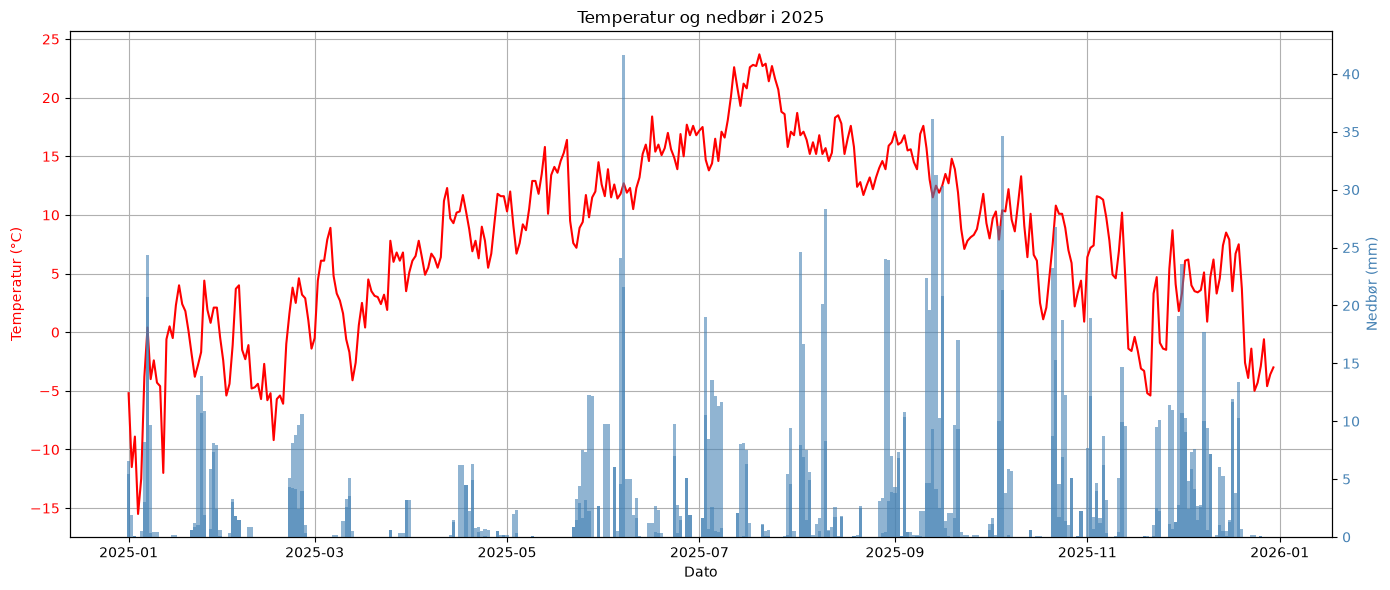

In [13]:
# Hent nedbørsdata

parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

r = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

json_data = r.json()

if r.status_code == 200:

    data = json_data["data"]

    rows = []

    for item in data:
        row = pd.DataFrame(item["observations"])
        row["referenceTime"] = item["referenceTime"]
        rows.append(row)

    df_precip = pd.concat(rows, ignore_index=True)

else:
    print(f"Feil! Statuskode: {r.status_code}")

# Klargjør nedbørsdata
df_precip["referenceTime"] = pd.to_datetime(df_precip["referenceTime"])

df_precip = df_precip[["referenceTime", "value"]]

df_precip.rename(
    columns={"value": "precipitation"},
    inplace=True
)

# Klargjør temperaturdata fra Task 1
df_temp = df[["referenceTime", "value"]].copy()

df_temp.rename(
    columns={"value": "temperature"},
    inplace=True
)

# Slå sammen temperatur og nedbør
weather = pd.merge(
    df_temp,
    df_precip,
    on="referenceTime",
    how="inner"
)

# Plot temperatur og nedbør i samme figur
fig, ax1 = plt.subplots(figsize=(14, 6))

# Temperatur som linje
ax1.plot(
    weather["referenceTime"],
    weather["temperature"],
    color="red",
    linewidth=1.5,
    label="Temperatur"
)

ax1.set_xlabel("Dato")
ax1.set_ylabel("Temperatur (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Nedbør som søyler
ax2 = ax1.twinx()

ax2.bar(
    weather["referenceTime"],
    weather["precipitation"],
    color="steelblue",
    alpha=0.6,
    width=1
)

ax2.set_ylabel("Nedbør (mm)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")

plt.title("Temperatur og nedbør i 2025")
ax1.grid(True)

plt.tight_layout()
plt.show()